# Discovering Molecular Families with Unsupervised Learning
### A beginner-friendly tutorial and graded chemistry homework (100 points)

Prof. Victor S. Batista

**CHEM 584: Introduction to Machine Learning and Quantum Computing**



**Audience:** Students who know introductory chemistry and Python but have never studied machine learning.  
**Main scientific question:** Can a computer group molecules into chemically meaningful families using numerical molecular properties **without being told the family names**?

**Learning goals:**
  1. distinguish supervised prediction from unsupervised discovery;
  2. construct interpretable molecular features;
  3. understand feature scaling, PCA, and K-means;
  4. choose cluster numbers without data leakage;
  5. examine a specialized *unsupervised random-forest proximity* approach;
  6. assess results cautiously using external reference labels and an optional supervised random-forest benchmark.

**Execution:** Run cells in order in Google Colab or Jupyter. The built-in dataset is included, so no Kaggle access is required. You may replace it with a documented chemical dataset in the extension. No need to run Gaussian.

## 0. What is learning from data?

A **data point** is one molecule. A **feature** is a number describing it, such as molecular weight or number of rings.

A **feature matrix** places molecules in rows and properties in columns.

In this assignment, we seek **clusters**: groups with similar feature values.

The algorithm does not initially know whether a molecule is an alcohol, acid, aromatic compound, or hydrocarbon.

  * **Supervised learning:** we train using known answers (labels), such as a column containing chemical family
  * **Unsupervised learning:** we discover patterns from features alone, without those answers.
  
A chemical family can later serve as an **external reference** to check whether discovered groups align with known chemistry, but such a match is not guaranteed—and chemical families can overlap.

**Important:** PCA does not discover chemical truth; it compresses variation. K-means does not discover unique, objectively true classes; it finds a partition according to a chosen mathematical criterion. A random-forest classifier is supervised. We will additionally demonstrate a **nonstandard unsupervised random-forest proximity construction**, explicitly distinguishing it from classification.

In [2]:
import sys, subprocess, importlib.util
if importlib.util.find_spec("rdkit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "rdkit"])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, Crippen, Lipinski
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (silhouette_score, adjusted_rand_score, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score)
from scipy.optimize import linear_sum_assignment
SEED = 42
np.random.seed(SEED)
print("Ready. scikit-learn and RDKit are installed.")

Ready. scikit-learn and RDKit are installed.


## 1. Build a small chemical dataset (worked example)

We begin with familiar small molecules. Each row has a name and SMILES—a text representation of atoms and bonds. The `family` column is a **reference annotation**, not input to the unsupervised algorithms. To avoid accidentally leaking known answers, we immediately separate it from the feature matrix.

**Chemistry caution:** Categories here are deliberately broad teaching labels; e.g., aromatic alcohols and aromatic acids can legitimately belong to more than one family. We choose distinct representative compounds to minimize ambiguity. These annotations are not an experimentally validated chemical classification database.

In [3]:
records = [
# Alkanes and cycloalkanes
("methane","C","hydrocarbon"),("ethane","CC","hydrocarbon"),("propane","CCC","hydrocarbon"),
("butane","CCCC","hydrocarbon"),("pentane","CCCCC","hydrocarbon"),("hexane","CCCCCC","hydrocarbon"),
("heptane","CCCCCCC","hydrocarbon"),("octane","CCCCCCCC","hydrocarbon"),
("cyclopentane","C1CCCC1","hydrocarbon"),("cyclohexane","C1CCCCC1","hydrocarbon"),
# Alcohols (non-aromatic, non-acidic)
("methanol","CO","alcohol"),("ethanol","CCO","alcohol"),("1-propanol","CCCO","alcohol"),
("1-butanol","CCCCO","alcohol"),("1-pentanol","CCCCCO","alcohol"),("1-hexanol","CCCCCCO","alcohol"),
("2-propanol","CC(C)O","alcohol"),("2-butanol","CCC(C)O","alcohol"),
("ethylene glycol","OCCO","alcohol"),("glycerol","OCC(O)CO","alcohol"),
# Carboxylic acids
("formic acid","O=CO","carboxylic acid"),("acetic acid","CC(=O)O","carboxylic acid"),
("propionic acid","CCC(=O)O","carboxylic acid"),("butyric acid","CCCC(=O)O","carboxylic acid"),
("pentanoic acid","CCCCC(=O)O","carboxylic acid"),("hexanoic acid","CCCCCC(=O)O","carboxylic acid"),
("heptanoic acid","CCCCCCC(=O)O","carboxylic acid"),("octanoic acid","CCCCCCCC(=O)O","carboxylic acid"),
("lactic acid","CC(O)C(=O)O","carboxylic acid"),("glycolic acid","OCC(=O)O","carboxylic acid"),
# Aromatic hydrocarbons
("benzene","c1ccccc1","aromatic"),("toluene","Cc1ccccc1","aromatic"),
("ethylbenzene","CCc1ccccc1","aromatic"),("propylbenzene","CCCc1ccccc1","aromatic"),
("xylene (o)","Cc1ccccc1C","aromatic"),("xylene (m)","Cc1cccc(C)c1","aromatic"),
("xylene (p)","Cc1ccc(C)cc1","aromatic"),("mesitylene","Cc1cc(C)cc(C)c1","aromatic"),
("naphthalene","c1ccc2ccccc2c1","aromatic"),("biphenyl","c1ccc(-c2ccccc2)cc1","aromatic")]
data = pd.DataFrame(records, columns=["name", "smiles", "family"])
print("Molecules:", len(data))
display(data.head(8))
assert len(data) == 40 and data.smiles.map(lambda s: Chem.MolFromSmiles(s) is not None).all()

Molecules: 40


,name,smiles,family
0,methane,C,hydrocarbon
1,ethane,CC,hydrocarbon
2,propane,CCC,hydrocarbon
3,butane,CCCC,hydrocarbon
4,pentane,CCCCC,hydrocarbon
5,hexane,CCCCCC,hydrocarbon
6,heptane,CCCCCCC,hydrocarbon
7,octane,CCCCCCCC,hydrocarbon


### How do molecular structures become numbers?

A computer cannot use molecule names directly as numerical coordinates. RDKit converts SMILES into a molecular graph and then computes **descriptors**: molecular weight (g/mol), logP (an estimated hydrophobicity measure), topological polar surface area (Å²), number of hydrogen-bond donors/acceptors, number of rings, fraction of sp³ carbons, and number of oxygen atoms. **These numerical descriptors are the inputs, not the `family` labels.**

A **feature matrix** `X` with 40 rows and 8 columns can be pictured as

$$
X = \begin{bmatrix} 	\text{MW}_1 & 	\text{logP}_1 & \cdots & 	\text{O atoms}_1\\
	\text{MW}_2 & 	\text{logP}_2 & \cdots & 	\text{O atoms}_2\\ \dots & \dots & & \dots \end{bmatrix}.
$$

Unlike polynomial regression, we do **not** add an intercept column: PCA and K-means analyze distances and directions in molecular feature space rather than fitting a regression intercept.

In [4]:
def molecular_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Cannot read SMILES: {smiles}")
    return {
        "MW": Descriptors.MolWt(mol),
        "logP": Crippen.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": Lipinski.NumHDonors(mol),
        "HBA": Lipinski.NumHAcceptors(mol),
        "rings": rdMolDescriptors.CalcNumRings(mol),
        "fraction_Csp3": rdMolDescriptors.CalcFractionCSP3(mol),
        "oxygen_atoms": sum(a.GetAtomicNum() == 8 for a in mol.GetAtoms()),
    }
features = pd.DataFrame([molecular_descriptors(s) for s in data.smiles])
X_raw = features.to_numpy(dtype=float)
y_reference = data.family.to_numpy()  # NEVER supplied to an unsupervised fit
print("Feature matrix shape:", X_raw.shape)
display(pd.concat([data[["name"]].head(5),features.head(5)],axis=1))
assert X_raw.shape == (40, 8)

Feature matrix shape: (40, 8)


,name,MW,logP,TPSA,HBD,HBA,rings,fraction_Csp3,oxygen_atoms
0,methane,16.043,0.6361,0.0,0,0,0,1.0,0
1,ethane,30.070,1.0262,0.0,0,0,0,1.0,0
2,propane,44.097,1.4163,0.0,0,0,0,1.0,0
3,butane,58.124,1.8064,0.0,0,0,0,1.0,0
4,pentane,72.151,2.1965,0.0,0,0,0,1.0,0


### Quick concept check (not graded)

1. How many numbers describe each molecule? Which columns are molecular features and which are metadata or reference labels?
2. Which feature measures the size of the molecule? Which features measure oxygen-containing functionality?
3. Why might a model group hexane and 1-hexanol together even though they have different functional groups?

## 2. Training, validation, test sets—and why clustering is special

A supervised classifier **learns from labels** and requires held-out testing. Unsupervised clustering learns from features; train/validation/test splits are **not required** to run K-means on a dataset, but can be useful when estimating how stable learned clusters are on new samples. We use a 60%/20%/20% split here for fair demonstrations. For this small pedagogical dataset, stratification keeps representatives from each reference family in each split; that stratification uses labels in the *experimental design*, **not in the unsupervised fitting**. In a genuinely unlabeled application, use a label-free split instead.

To prevent **data leakage**, fit the feature scaler and PCA on training molecules only. Apply the same fitted transformations to validation and test molecules. If the dataset contains close analogues or near duplicates, random splitting can overstate generalization; scaffold-based splitting is a useful advanced alternative.

In [5]:
ids = np.arange(len(data))
train_ids, other_ids = train_test_split(ids, test_size=0.40, random_state=SEED, stratify=y_reference)
val_ids, test_ids = train_test_split(other_ids, test_size=0.50, random_state=SEED, stratify=y_reference[other_ids])
scaler = StandardScaler().fit(X_raw[train_ids])
X_train = scaler.transform(X_raw[train_ids])
X_val = scaler.transform(X_raw[val_ids])
X_test = scaler.transform(X_raw[test_ids])
print("Train/validation/test:",len(train_ids),len(val_ids),len(test_ids))
print("Training feature means (rounded):",np.round(X_train.mean(axis=0),3))

Train/validation/test: 24 8 8
Training feature means (rounded): [ 0.  0.  0. -0. -0.  0. -0.  0.]


## 3. Why do we standardize features?

Molecular weight is often tens or hundreds, whereas ring count may only be 0, 1, or 2. Without adjustment, a difference of 30 g/mol can overwhelm a difference of one ring when Euclidean distance is used.

**Standardization** transforms each training-set column using
$$
z = \frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}},
$$
where `μ_train` is the column mean and `σ_train` is the population standard deviation calculated on the **training set only**. Example: molecular weights of 30, 40, 50 have mean 40 and standard deviation about 8.16; 50 standardizes to about 1.22.

This makes the numerical scales more comparable; it does **not** make correlated or redundant descriptors independent. Descriptor choices materially influence discovered groups.

Example: mean=40.00, standard deviation=8.16, transformed 50=1.225


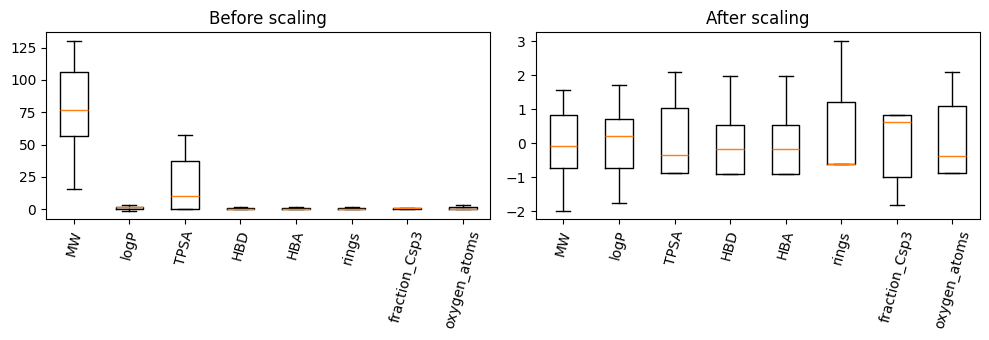

In [6]:
weights = np.array([30., 40., 50.])
mu = weights.mean(); sd = weights.std()
print(f"Example: mean={mu:.2f}, standard deviation={sd:.2f}, transformed 50={(50-mu)/sd:.3f}")
fig, ax = plt.subplots(1,2, figsize=(10,3.5))
ax[0].boxplot(X_raw[train_ids],tick_labels=features.columns,vert=True);ax[0].tick_params(axis='x',rotation=75);ax[0].set_title('Before scaling')
ax[1].boxplot(X_train,tick_labels=features.columns,vert=True);ax[1].tick_params(axis='x',rotation=75);ax[1].set_title('After scaling')
plt.tight_layout();plt.show()

## 4. Principal component analysis (PCA), step by step

Imagine plotting molecules using just two descriptors. Eight descriptors require eight coordinate axes, which are difficult to visualize. PCA constructs new axes, called **principal components**, which are weighted combinations of the original standardized features. The first component captures the largest remaining variance, the second captures the next largest while remaining perpendicular to the first, and so on.

For example, a possible principal component is
$$
\mathrm{PC1}=0.5z_{
m MW}+0.4z_{
m logP}-0.3z_{
m TPSA}+\cdots.
$$
These coefficients are **loadings**; their signs are arbitrary up to an overall sign flip.

**Explained variance ratio** tells us how much of the total feature variance is captured by each axis—not what percentage of chemical classes PCA identifies.

We calculate PCA using training molecules and then project validation and test molecules into that fixed coordinate system. The PCA visualization is descriptive; we will cluster on **all eight standardized features** to avoid silently discarding information.

Variance explained by PC1 and PC2: [0.632 0.215]
Combined variance explained: 0.847


,PC1 loading,PC2 loading
MW,-0.135,0.584
logP,-0.386,0.135
TPSA,0.417,0.243
HBD,0.429,0.157
HBA,0.429,0.157
rings,-0.313,0.403
fraction_Csp3,0.149,-0.554
oxygen_atoms,0.413,0.252


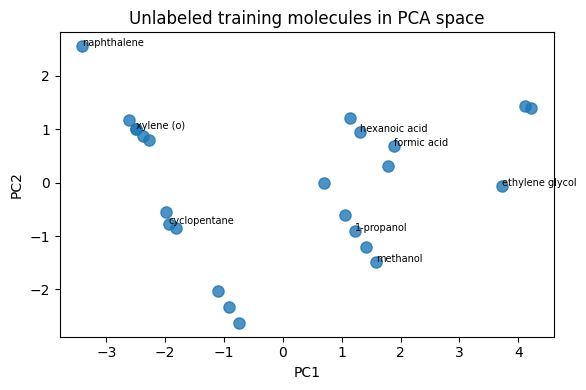

In [7]:
pca = PCA(n_components=2).fit(X_train)
Z_train = pca.transform(X_train)
Z_val = pca.transform(X_val)
Z_test = pca.transform(X_test)
print("Variance explained by PC1 and PC2:",np.round(pca.explained_variance_ratio_,3))
print("Combined variance explained:",round(pca.explained_variance_ratio_.sum(),3))
display(pd.DataFrame(pca.components_.T,index=features.columns,columns=["PC1 loading","PC2 loading"]).round(3))
fig,ax=plt.subplots(figsize=(6,4))
ax.scatter(Z_train[:,0],Z_train[:,1],s=65,alpha=.8)
for i,idx in enumerate(train_ids):
    if i%3==0:ax.annotate(data.name.iloc[idx],(Z_train[i,0],Z_train[i,1]),fontsize=7)
ax.set(xlabel='PC1',ylabel='PC2',title='Unlabeled training molecules in PCA space')
plt.tight_layout();plt.show()

## 5. K-means clustering from first principles

**K-means** groups data into `K` groups. Each group has a **centroid**, the mean location of its assigned molecules. It repeats two steps: (1) assign every molecule to its closest centroid, (2) recompute centroids as group averages. It tries to minimize within-cluster squared distances (**inertia**):
$$
J=\sum_{i=1}^{N}\left\|\mathbf{x}_i-{\mu}_{c_i}
\right\|^2.
$$
Here $x_i$ is molecule $i$'s feature vector, $c_i$ is the cluster assigned to it, and `μ` is the centroid of that cluster. $K=4$ means four groups, **not automatically four chemical families**. Labels 0, 1, 2, 3 are arbitrary identifiers.

**Toy example:** points at 1, 2, 9, 10 with `K=2` naturally form {1,2} and {9,10}; their centroids are 1.5 and 9.5. But for real chemicals clusters can overlap, be unbalanced, or have non-spherical shapes.

Toy group centroids: [np.float64(1.5), np.float64(9.5)]
Training group sizes: [4 6 8 6]
Training inertia: 44.55


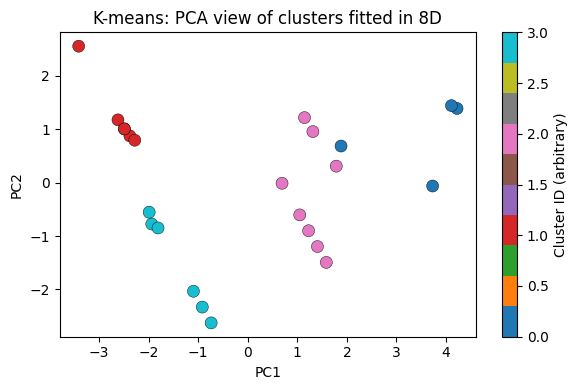

In [8]:
toy=np.array([1.,2.,9.,10.]);toy_labels=np.array([0,0,1,1])
print("Toy group centroids:", [toy[toy_labels==k].mean() for k in [0,1]])
km_demo=KMeans(n_clusters=4,n_init=20,random_state=SEED).fit(X_train)
print("Training group sizes:",np.bincount(km_demo.labels_,minlength=4))
print("Training inertia:",round(km_demo.inertia_,3))
fig,ax=plt.subplots(figsize=(6,4))
sc=ax.scatter(Z_train[:,0],Z_train[:,1],c=km_demo.labels_,cmap='tab10',s=75,edgecolor='k',linewidth=.3)
ax.set(xlabel='PC1',ylabel='PC2',title='K-means: PCA view of clusters fitted in 8D')
plt.colorbar(sc,ax=ax,label='Cluster ID (arbitrary)');plt.tight_layout();plt.show()

## 6. Choosing K: inertia and silhouette score

`K` is a **hyperparameter** selected by the analyst. Inertia always tends to decrease as `K` increases, so simply choosing the smallest inertia is misleading. The **silhouette score** compares how close a molecule is to its own cluster versus the nearest other cluster. Its range is approximately −1 (likely poorly assigned) to +1 (well separated). We first compare candidate values on training data, then inspect validation performance. We **do not** use the test set to choose `K`.

High silhouette does not prove that groups are chemically meaningful: a cluster could merely separate heavy from light molecules. We inspect descriptor summaries and molecules in each group before drawing chemical conclusions.

,K,train_inertia,train_silhouette,validation_silhouette
0,2,94.040,0.427,0.540
1,3,64.134,0.436,0.566
2,4,44.550,0.428,0.566
3,5,33.742,0.442,0.244
4,6,24.255,0.479,0.197


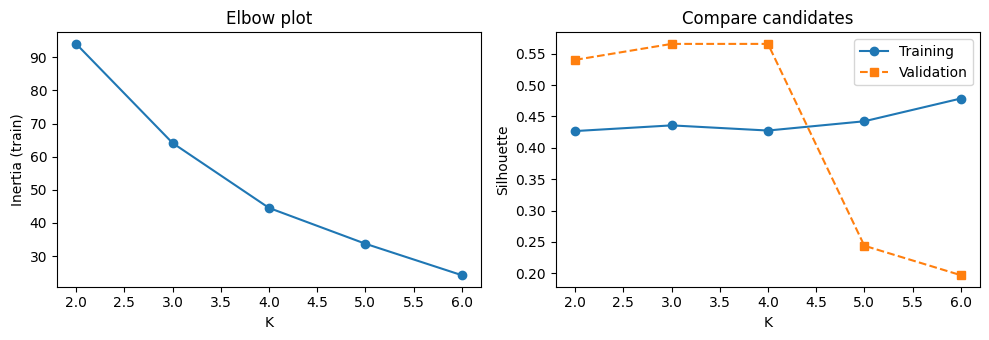

Selected K using validation silhouette only: 3


In [9]:
candidate_k=[2,3,4,5,6]
rows=[]
for k in candidate_k:
    model=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(X_train)
    val_clusters=model.predict(X_val)
    val_sil=silhouette_score(X_val,val_clusters) if len(set(val_clusters))>1 and len(set(val_clusters))<len(val_clusters) else np.nan
    rows.append({"K":k,"train_inertia":model.inertia_,"train_silhouette":silhouette_score(X_train,model.labels_),"validation_silhouette":val_sil})
search=pd.DataFrame(rows)
display(search.round(3))
fig, ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(search.K,search.train_inertia,'o-');ax[0].set(xlabel='K',ylabel='Inertia (train)',title='Elbow plot')
ax[1].plot(search.K,search.train_silhouette,'o-',label='Training')
ax[1].plot(search.K,search.validation_silhouette,'s--',label='Validation')
ax[1].set(xlabel='K',ylabel='Silhouette',title='Compare candidates');ax[1].legend()
plt.tight_layout();plt.show()
# For a transparent demonstration: select K using validation silhouette ONLY.
valid=search.dropna(subset=['validation_silhouette'])
best_k=int(valid.loc[valid.validation_silhouette.idxmax(),'K'])
print('Selected K using validation silhouette only:',best_k)

## 7. Interpret clusters using chemistry (and external labels only afterward)

Unlike a classifier, K-means did **not** learn a mapping between features and the known `family` column. We can examine which molecules fall in a cluster, average its descriptors, and discuss why they are similar. We may compare to the withheld reference labels *after training*, but reference agreement is not required for a scientifically interesting cluster.

**ARI**, the adjusted Rand index, measures agreement between two group assignments without requiring cluster numbers to match label numbers. ARI = 1 indicates perfect agreement, ARI near 0 indicates chance-level agreement under its reference model, and negative scores are possible. An ARI is not classification accuracy.

A **confusion matrix** requires an explicit mapping from cluster IDs to reference class names if interpreted as classification. We show such a mapping only for descriptive evaluation. It is learned using training reference labels and then frozen for test scoring. Cluster count can differ from reference class count, and some classes may lack a corresponding cluster; in that case a simple one-to-one mapping is inappropriate.

In [10]:
# Refit only on labeled-free training+validation FEATURES after choosing K, keeping test unseen.
fit_ids=np.concatenate([train_ids,val_ids])
scaler_final=StandardScaler().fit(X_raw[fit_ids])
X_fit=scaler_final.transform(X_raw[fit_ids]);X_holdout=scaler_final.transform(X_raw[test_ids])
km_final=KMeans(n_clusters=best_k,n_init=20,random_state=SEED).fit(X_fit)
clusters_fit=km_final.labels_;clusters_test=km_final.predict(X_holdout)
summary=features.iloc[fit_ids].copy();summary['cluster']=clusters_fit
print('Mean chemical descriptors for each cluster:')
display(summary.groupby('cluster').mean().round(2))
print('Independent holdout ARI (uses reference labels only for evaluation):',round(adjusted_rand_score(y_reference[test_ids],clusters_test),3))
print('Cluster-versus-family counts (descriptive only):')
display(pd.crosstab(pd.Series(y_reference[test_ids],name='reference family'),pd.Series(clusters_test,name='K-means cluster')))

Mean chemical descriptors for each cluster:


,MW,logP,TPSA,HBD,HBA,rings,fraction_Csp3,oxygen_atoms
cluster,,,,,,,,
0,78.85,0.49,32.56,1.19,1.19,0.00,0.82,1.69
1,107.17,2.34,0.00,0.00,0.00,1.12,0.19,0.00
2,64.63,1.94,0.00,0.00,0.00,0.25,1.00,0.00


Independent holdout ARI (uses reference labels only for evaluation): 0.588
Cluster-versus-family counts (descriptive only):


K-means cluster,0,1,2
reference family,,,
alcohol,2,0,0
aromatic,0,2,0
carboxylic acid,2,0,0
hydrocarbon,0,0,2


### What about cluster “accuracy” and confusion matrices?

You can *optionally* translate each cluster into a family name using a majority vote on **training+validation reference annotations**, then evaluate the fixed mapping on the test data. This procedure uses labels during the interpretation step; the original clustering remains unsupervised. If the model produces two clusters that correspond to the same family, both may receive that family name. This conversion is a **post-hoc classifier**, and its accuracy is **not a purely unsupervised metric**. We report ARI alongside it.

Fixed post-hoc cluster mapping: {0: 'alcohol', 1: 'aromatic', 2: 'hydrocarbon'}
Post-hoc test accuracy (label-dependent): 0.75


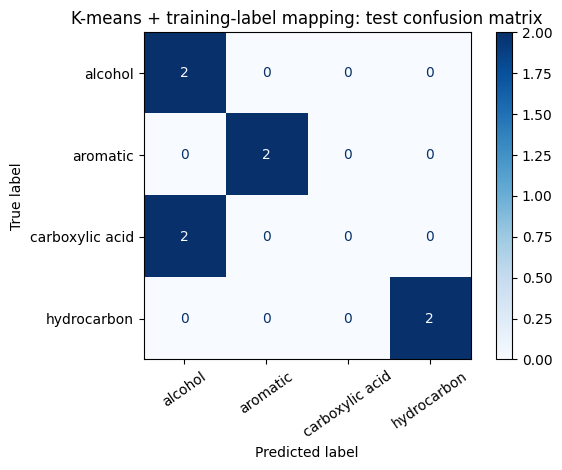

In [11]:
def map_clusters_to_majority(cluster_train, labels_train):
    mapping={}
    for c in np.unique(cluster_train):
        values, counts=np.unique(labels_train[cluster_train==c],return_counts=True)
        mapping[int(c)]=str(values[np.argmax(counts)])
    return mapping
mapping=map_clusters_to_majority(clusters_fit,y_reference[fit_ids])
km_test_prediction=np.array([mapping[int(c)] for c in clusters_test])
print('Fixed post-hoc cluster mapping:',mapping)
print('Post-hoc test accuracy (label-dependent):',round(accuracy_score(y_reference[test_ids],km_test_prediction),3))
classes=np.unique(y_reference)
ConfusionMatrixDisplay.from_predictions(y_reference[test_ids],km_test_prediction,labels=classes,xticks_rotation=35,cmap='Blues')
plt.title('K-means + training-label mapping: test confusion matrix');plt.tight_layout();plt.show()

## 8. Random forests: supervised classification versus unsupervised proximity

A normal **random forest classifier** trains many decision trees on features **and known target labels**. Each tree proposes a class, and the forest votes. This is **supervised** learning. It is a valuable comparison: if we explicitly supply reference family labels, how well can a model predict those annotations from the chosen descriptors?

An **unsupervised random-forest proximity** approach is different and less standard: generate synthetic data by independently shuffling feature columns; train a forest to distinguish real feature combinations from shuffled combinations; represent how often two *real* molecules land in the same decision-tree leaves as a similarity; and cluster that similarity. **This is not a supervised random-forest classifier of chemical families.** The synthetic-vs-real task creates its own training labels (not chemical family labels). Interpret the result cautiously, especially in a small dataset.

### 8A. Optional supervised reference benchmark (not an unsupervised model)

We compare several tree settings using a validation split. The test set remains untouched until we select the forest. We fit with *chemical family labels* here and say so explicitly.

,n_trees,min_samples_leaf,validation_accuracy
0,30,2,1.000
1,100,2,0.875
2,100,4,1.000
3,200,2,0.875


Selected supervised RF test accuracy: 0.875


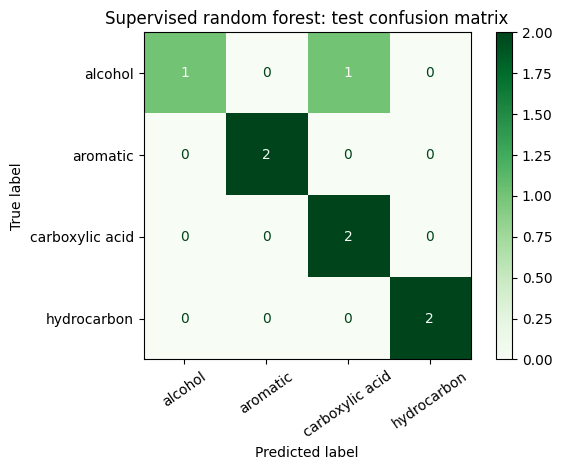

In [12]:
rf_rows=[]; rf_options=[(30,2),(100,2),(100,4),(200,2)]
for ntrees,leaf in rf_options:
    model=RandomForestClassifier(n_estimators=ntrees,min_samples_leaf=leaf,random_state=SEED)
    model.fit(X_train,y_reference[train_ids])
    rf_rows.append({'n_trees':ntrees,'min_samples_leaf':leaf,'validation_accuracy':accuracy_score(y_reference[val_ids],model.predict(X_val))})
rf_table=pd.DataFrame(rf_rows)
display(rf_table)
choice=rf_table.sort_values(['validation_accuracy','n_trees'],ascending=[False,True]).iloc[0]
rf_supervised=RandomForestClassifier(n_estimators=int(choice.n_trees),min_samples_leaf=int(choice.min_samples_leaf),random_state=SEED).fit(X_fit,y_reference[fit_ids])
rf_test_prediction=rf_supervised.predict(X_holdout)
print('Selected supervised RF test accuracy:',round(accuracy_score(y_reference[test_ids],rf_test_prediction),3))
ConfusionMatrixDisplay.from_predictions(y_reference[test_ids],rf_test_prediction,labels=classes,xticks_rotation=35,cmap='Greens')
plt.title('Supervised random forest: test confusion matrix');plt.tight_layout();plt.show()

### 8B. Demonstration: unsupervised random-forest proximities

To avoid letting test molecules influence the fitting, we construct the synthetic and real-vs-synthetic discriminator using **training+validation features only**. We compute similarity between holdout molecules using tree leaves and convert it to hierarchical clusters. This is a didactic implementation—not a universally standardized unsupervised-forest algorithm. We choose the number of clusters from the previously selected `best_k`; no tuning uses test annotations.

A proximity of 1 means two molecules land in the same leaf in every tree; 0 means never. We convert proximity to dissimilarity `1 − proximity`. Hierarchical clustering can use this precomputed dissimilarity matrix. Because it clusters test molecules jointly, it is **transductive**, not a trained model that assigns independent new molecules without revisiting the test group.

Unsupervised RF-proximity test ARI (external labels used only for score): 0.329


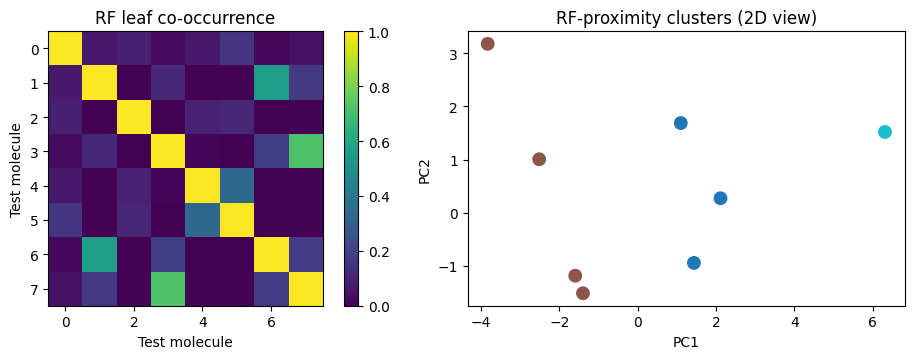

In [13]:
rng=np.random.default_rng(SEED)
X_synth=np.column_stack([rng.permutation(X_fit[:,j]) for j in range(X_fit.shape[1])])
X_binary=np.vstack([X_fit,X_synth]); y_binary=np.r_[np.ones(len(X_fit),dtype=int),np.zeros(len(X_synth),dtype=int)]
rf_proximity=RandomForestClassifier(n_estimators=150,min_samples_leaf=2,max_features='sqrt',random_state=SEED).fit(X_binary,y_binary)
leaves=rf_proximity.apply(X_holdout) # shape (test molecules, trees)
proximity=(leaves[:,None,:]==leaves[None,:,:]).mean(axis=2)
distance=1.0-proximity
np.fill_diagonal(distance,0.0)
urfc_clusters=AgglomerativeClustering(n_clusters=best_k,metric='precomputed',linkage='average').fit_predict(distance)
print('Unsupervised RF-proximity test ARI (external labels used only for score):',round(adjusted_rand_score(y_reference[test_ids],urfc_clusters),3))
fig,ax=plt.subplots(1,2,figsize=(10,3.7))
im=ax[0].imshow(proximity,vmin=0,vmax=1,cmap='viridis');ax[0].set(title='RF leaf co-occurrence',xlabel='Test molecule',ylabel='Test molecule');plt.colorbar(im,ax=ax[0])
pca_final=PCA(n_components=2).fit(X_fit)
Z_holdout=pca_final.transform(X_holdout)
sc=ax[1].scatter(Z_holdout[:,0],Z_holdout[:,1],c=urfc_clusters,cmap='tab10',s=80)
ax[1].set(xlabel='PC1',ylabel='PC2',title='RF-proximity clusters (2D view)')
plt.tight_layout();plt.show()

## 9. Comparison table—and how to read it

The first two rows are **unsupervised** groupings, compared with reference chemical-family labels using ARI. The third row is **supervised**, so its test accuracy answers a different question. The post-hoc K-means accuracy uses a fitted majority-vote mapping. We deliberately leave classification accuracy blank for pure unsupervised RF-proximity clustering because no out-of-sample class-name mapper was trained.

In [14]:
result_table=pd.DataFrame([
    {'Method':'K-means clustering','Learning':'Unsupervised','Test ARI':adjusted_rand_score(y_reference[test_ids],clusters_test),'Test accuracy (if applicable)':np.nan},
    {'Method':'K-means + fitted label mapping','Learning':'Unsupervised clustering + supervised interpretation','Test ARI':adjusted_rand_score(y_reference[test_ids],clusters_test),'Test accuracy (if applicable)':accuracy_score(y_reference[test_ids],km_test_prediction)},
    {'Method':'RF proximity + hierarchical clustering','Learning':'Unsupervised proximity construction','Test ARI':adjusted_rand_score(y_reference[test_ids],urfc_clusters),'Test accuracy (if applicable)':np.nan},
    {'Method':'RF classifier','Learning':'Supervised','Test ARI':np.nan,'Test accuracy (if applicable)':accuracy_score(y_reference[test_ids],rf_test_prediction)}])
display(result_table.round(3))
print('Caution: 8 test molecules cannot support precise generalization claims.')

,Method,Learning,Test ARI,Test accuracy (if applicable)
0,K-means clustering,Unsupervised,0.588,NaN
1,K-means + fitted label mapping,Unsupervised clustering + supervised interpret...,0.588,0.750
2,RF proximity + hierarchical clustering,Unsupervised proximity construction,0.329,NaN
3,RF classifier,Supervised,NaN,0.875


Caution: 8 test molecules cannot support precise generalization claims.


## 10. Uploaded `co2.log`: interpreting one quantum-chemistry result

The uploaded `co2.log` is a Gaussian 16 calculation for **one CO₂ molecule**, including computed structural and vibrational properties. It is useful for teaching where *computational chemistry descriptors* can originate, but **one molecule is not a clustering dataset**. We must compute matching descriptors across many molecules before using a Gaussian-derived feature matrix for unsupervised learning.

The file reports an initial C–O distance of about 1.2584 Å and harmonic frequencies about 690.4 (twice), 990.4, and 1716.7 cm⁻¹ in a printed section. These values are specific to the supplied calculation/geometry and should not be represented as a validated experimental spectrum. The example parser below retrieves the **first printed harmonic-frequency block** if the log is available; optional upload support works in Colab as well.

In [15]:
from pathlib import Path
import re
log_path = Path('co2.log')
if not log_path.exists() and Path('/mnt/data/co2.log').exists():
    log_path=Path('/mnt/data/co2.log')
if log_path.exists():
    log_text=log_path.read_text(errors='replace')
    first_freq=re.search(r'^\s*Frequencies\s*--\s*(.+)$',log_text,re.MULTILINE)
    if first_freq:
        freq=[float(number) for number in first_freq.group(1).split()]
        print('First reported harmonic frequencies (cm^-1):',freq)
    print('Found Gaussian file:',log_path.name)
else:
    print('Optional co2.log not found. Upload it if you want to examine the Gaussian example.')

Optional co2.log not found. Upload it if you want to examine the Gaussian example.


## 11. Homework tasks — 100 points

**Instructions:** Execute the complete notebook. Complete each task below **in your own Markdown and code cells**; do not alter the fixed reference-family annotations to improve scores. Show calculations, graphs, and interpretation. Avoid claims of predictive superiority on this small toy dataset. If you use an external chemistry dataset, cite its source and document cleaning.

### Task 1 — Molecules as data (15 points)
- **5 pts:** Identify inputs, external reference labels, sample count, and descriptor count. Describe three features chemically.
- **5 pts:** Explain why label columns must not enter unsupervised training; give an example of data leakage.
- **5 pts:** Show the descriptor table for two molecules and explain two chemically meaningful differences.

**Deliverable:** One table and ~150 words of explanation.

### Task 2 — Standardization and PCA (20 points)
- **5 pts:** By hand, standardize the value 50 from [30,40,50], showing mean and standard deviation.
- **5 pts:** Explain why standardization matters for Euclidean distances.
- **5 pts:** Report the fraction of training variance explained by PC1 and PC2; identify two large-magnitude loadings.
- **5 pts:** Produce a labeled PCA plot and describe the limits of interpreting its apparent separation.

**Deliverable:** One hand calculation, one plot, ~150–250 words.

### Task 3 — K-means and hyperparameters (25 points)
- **5 pts:** Explain centroids, assignments, and inertia in your own words.
- **8 pts:** Compare at least three `K` choices and show inertia and silhouette scores in a table and plot.
- **7 pts:** Explain your chosen `K` using training/validation information **without inspecting test labels**.
- **5 pts:** List representative molecules and mean properties for each learned cluster; interpret chemistry.

**Deliverable:** Comparison table, two plots, chemical interpretation.

### Task 4 — Random forests and evaluation (25 points)
- **7 pts:** Explain why a standard random-forest classifier is supervised and how the real-vs-shuffled unsupervised proximity construction differs.
- **5 pts:** Compare at least three supervised RF hyperparameter settings using validation data.
- **8 pts:** Report test results for K-means, RF proximity, and supervised RF **using appropriate metrics**; include a labeled confusion matrix for the supervised RF and/or the explicitly mapped K-means result.
- **5 pts:** Discuss why raw cluster IDs cannot be inserted into a conventional accuracy calculation without label mapping, and interpret ARI.

**Deliverable:** Results table, confusion matrix, ~200 words.

### Task 5 — Scientific critique and new method (15 points)
- **5 pts:** Explain limitations of this small chemical dataset (size, overlap, feature choice, close analogues).
- **5 pts:** Describe one additional clustering method (DBSCAN or Gaussian mixture model); state a dataset where it may be preferable.
- **5 pts:** Explain whether `co2.log` alone can be clustered and propose three Gaussian-derived features that **could** be obtained consistently for many molecules.

**Deliverable:** ~200–300 words of scientific discussion.

**Submit:**

  * (i). one executed `.ipynb` notebook with all original output plots visible;
  * (ii) written answers entered in Markdown next to each task (no separate report necessary);
  * (iii) source attribution for any outside dataset/code.

**Total = 100 points.**

**General grading principle:** Full credit requires correct results *and* a scientifically justified explanation; unannotated code and unexplained plots will not receive full credit. Write your own answers and follow course academic-integrity expectations.

### Student response — Task 1: Molecules as data

**Your written response:** Add your descriptor comparison table and answers.  
*Replace this line with your answer. Add new code cells below as needed.*

In [16]:
# STUDENT TASK 1: add your calculations or plots here.
# Existing worked code above is available as a starting point.
pass

### Student response — Task 2: Standardization and PCA

**Your written response:** Show the hand calculation, PCA visualization, and interpretation.  
*Replace this line with your answer. Add new code cells below as needed.*

In [17]:
# STUDENT TASK 2: add your calculations or plots here.
# Existing worked code above is available as a starting point.
pass

### Student response — Task 3: K-means model selection

**Your written response:** Show your K comparison, model-selection reasoning, and chemical interpretation.  
*Replace this line with your answer. Add new code cells below as needed.*

In [18]:
# STUDENT TASK 3: add your calculations or plots here.
# Existing worked code above is available as a starting point.
pass

### Student response — Task 4: Random forests and evaluation

**Your written response:** Show the hyperparameter table, metrics, confusion matrix, and interpretation.  
*Replace this line with your answer. Add new code cells below as needed.*

In [19]:
# STUDENT TASK 4: add your calculations or plots here.
# Existing worked code above is available as a starting point.
pass

### Student response — Task 5: Scientific critique

**Your written response:** Discuss limitations, an alternative clustering algorithm, and Gaussian-derived features.  
*Replace this line with your answer. Add new code cells below as needed.*

In [20]:
# STUDENT TASK 5: add your calculations or plots here.
# Existing worked code above is available as a starting point.
pass

## 12. Optional extension: analyze your own Kaggle chemical dataset

To preserve the original assignment's flexibility, students may substitute a documented dataset of **multiple molecules**. Show a sample table, clean missing values, identify valid numerical features, keep any reference class separate, fit transformations on training data only, and repeat the analysis. If the dataset lacks known classes, report cluster quality/stability and chemical interpretation but **do not invent accuracy or confusion matrices**. If classes are present, use them only after unsupervised fitting for external evaluation.

### Checklist before submission
- All notebook cells execute in order.
- A plot has axes/units and legends where needed.
- Cluster IDs are not confused with chemical family labels.
- No test-set information was used to select preprocessing, `K`, or RF hyperparameters.
- Answers discuss what results mean chemically rather than only quoting scores.